# 1. Set-Up Environment

In [34]:
# import library yang dibutuhkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict
from sklearn.naive_bayes import GaussianNB
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)

In [35]:
# pengaturan tampilan tabel & grafik
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)
sns.set_style('whitegrid')

# 2. Memahami Karakteristik Dataset 

In [36]:
# membaca dataset
df = pd.read_csv('credit_risk_dataset.csv')
print(f"Dimensi Awal Dataset : {df.shape[0]} baris x {df.shape[1]} kolom\n")

Dimensi Awal Dataset : 32581 baris x 12 kolom



In [37]:
# menampilkan sampel 5 baris pertama dataset
print("A. Sampel 5 Baris Pertama Dataset Asli")
display(df.head())

A. Sampel 5 Baris Pertama Dataset Asli


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [38]:
# menampilkan informasi tipe data dan missing values
print("\nB. Informasi Tipe Data & Missing Values")
info_df = pd.DataFrame({
    'Tipe Data': df.dtypes,
    'Jumlah Non-Null': df.notnull().sum(),
    'Missing Values': df.isnull().sum(),
    'Persentase Missing (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
display(info_df)


B. Informasi Tipe Data & Missing Values


,Tipe Data,Jumlah Non-Null,Missing Values,Persentase Missing (%)
person_age,int64,32581,0,0.00
person_income,int64,32581,0,0.00
person_home_ownership,str,32581,0,0.00
person_emp_length,float64,31686,895,2.75
loan_intent,str,32581,0,0.00
loan_grade,str,32581,0,0.00
loan_amnt,int64,32581,0,0.00
loan_int_rate,float64,29465,3116,9.56
loan_status,int64,32581,0,0.00
loan_percent_income,float64,32581,0,0.00


In [39]:
# menampilkan statistik deskriptif fitur numerik
print("\nC. Statistik Deskriptif Fitur Numerik (Sebelum Cleaning)")
display(df.describe().round(2))


C. Statistik Deskriptif Fitur Numerik (Sebelum Cleaning)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.00,32581.00,31686.00,32581.00,29465.00,32581.00,32581.00,32581.00
mean,27.73,66074.85,4.79,9589.37,11.01,0.22,0.17,5.80
std,6.35,61983.12,4.14,6322.09,3.24,0.41,0.11,4.06
min,20.00,4000.00,0.00,500.00,5.42,0.00,0.00,2.00
25%,23.00,38500.00,2.00,5000.00,7.90,0.00,0.09,3.00
50%,26.00,55000.00,4.00,8000.00,10.99,0.00,0.15,4.00
75%,30.00,79200.00,7.00,12200.00,13.47,0.00,0.23,8.00
max,144.00,6000000.00,123.00,35000.00,23.22,1.00,0.83,30.00


In [40]:
# menampilkan jumlah baris duplikat dan anomali data
print("\nD. Pengecekan Duplikasi & Anomali Data")
print(f"• Jumlah baris duplikat persis          : {df.duplicated().sum()} baris")
print(f"• Anomali usia tidak wajar (> 80 tahun) : {(df['person_age'] > 80).sum()} baris")
print(f"• Anomali masa kerja (> 60 tahun)       : {(df['person_emp_length'] > 60).sum()} baris")


D. Pengecekan Duplikasi & Anomali Data
• Jumlah baris duplikat persis          : 165 baris
• Anomali usia tidak wajar (> 80 tahun) : 7 baris
• Anomali masa kerja (> 60 tahun)       : 2 baris


In [41]:
# menampilkan distribusi kelas target (loan_status)
print("\nE. Distribusi Kelas Target (loan_status)")
target_dist = pd.DataFrame({
    'Jumlah Data': df['loan_status'].value_counts(),
    'Persentase (%)': (df['loan_status'].value_counts(normalize=True) * 100).round(2)
})
target_dist.index = ['0 (Lancar / Non-Default)', '1 (Gagal Bayar / Default)']
display(target_dist)


E. Distribusi Kelas Target (loan_status)


,Jumlah Data,Persentase (%)
0 (Lancar / Non-Default),25473,78.18
1 (Gagal Bayar / Default),7108,21.82


# 3. Data Preprocessing & Data Cleaning 

In [42]:
# membuat salinan dataset untuk proses cleaning
df_clean = df.copy()

In [43]:
# menghapus baris duplikat
awal_baris = len(df_clean)
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"A. Hapus Duplikasi        : {awal_baris} -> {len(df_clean)} baris (dibuang {awal_baris - len(df_clean)} duplikat)")

A. Hapus Duplikasi        : 32581 -> 32416 baris (dibuang 165 duplikat)


In [44]:
# menghapus anomali usia > 80 tahun dan masa kerja > 60 tahun
sebelum_anomali = len(df_clean)
df_clean = df_clean[df_clean['person_age'] <= 80]
df_clean = df_clean[(df_clean['person_emp_length'] <= 60) | (df_clean['person_emp_length'].isna())]
df_clean = df_clean.reset_index(drop=True)
print(f"B. Hapus Anomali Ekstrem  : {sebelum_anomali} -> {len(df_clean)} baris (dibuang {sebelum_anomali - len(df_clean)} anomali)")

B. Hapus Anomali Ekstrem  : 32416 -> 32407 baris (dibuang 9 anomali)


In [45]:
# imputasi nilai kosong dengan median
median_emp = df_clean['person_emp_length'].median()
median_rate = df_clean['loan_int_rate'].median()
df_clean['person_emp_length'] = df_clean['person_emp_length'].fillna(median_emp)
df_clean['loan_int_rate'] = df_clean['loan_int_rate'].fillna(median_rate)
print(f"C. Imputasi Median        : person_emp_length = {median_emp}, loan_int_rate = {median_rate}")
print(f"   Total Missing Tersisa  : {df_clean.isnull().sum().sum()} nilai kosong")

C. Imputasi Median        : person_emp_length = 4.0, loan_int_rate = 10.99
   Total Missing Tersisa  : 0 nilai kosong


In [46]:
# membuat salinan dataset untuk proses EDA
df_eda = df_clean.copy()

In [47]:
# mengubah tipe data fitur kategorikal menjadi numerik
grade_mapping = {'A': 0, 'B': 1, 'C': 2, 'D': 3, 'E': 4, 'F': 5, 'G': 6}
default_mapping = {'N': 0, 'Y': 1}
df_clean['loan_grade'] = df_clean['loan_grade'].map(grade_mapping)
df_clean['cb_person_default_on_file'] = df_clean['cb_person_default_on_file'].map(default_mapping)

df_encoded = pd.get_dummies(
    df_clean,
    columns=['person_home_ownership', 'loan_intent'],
    drop_first=True,
    dtype=int
)

X = df_encoded.drop('loan_status', axis=1)
y = df_encoded['loan_status']

In [48]:
# menampilkan preview data setelah encoding dan scaling
scaler_preview = StandardScaler()
X_scaled_preview = pd.DataFrame(scaler_preview.fit_transform(X), columns=X.columns)

print(f"\nD. Encoding & Scaling     : Menghasilkan {X.shape[1]} fitur numerik siap latih.")


D. Encoding & Scaling     : Menghasilkan 17 fitur numerik siap latih.


In [49]:
# menampilkan sampel 5 baris data setelah encoding dan scaling
print("\nSampel 5 Baris Data Setelah Encoding & StandardScaler")
display(X_scaled_preview.head().round(4))


Sampel 5 Baris Data Setelah Encoding & StandardScaler


,person_age,person_income,person_emp_length,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE
0,-1.0864,-1.0719,0.0598,-0.1889,-1.3594,0.0407,-0.6578,-0.4634,-0.9396,-0.0573,3.4124,-1.0105,2.0141,-0.3532,-0.4787,-0.4519,-0.4609
1,-0.4404,-1.0719,-0.9442,0.6678,-0.6475,0.6018,3.7435,-0.4634,-0.6930,-0.0573,-0.2931,-1.0105,-0.4965,-0.3532,2.0891,-0.4519,-0.4609
2,-0.7634,-0.0075,-0.1912,0.6678,4.0196,1.3673,3.3690,-0.4634,-0.9396,-0.0573,-0.2931,0.9896,-0.4965,-0.3532,2.0891,-0.4519,-0.4609
3,-0.6019,-0.2189,0.8129,0.6678,4.0196,1.0559,3.5563,2.1579,-0.4464,-0.0573,-0.2931,0.9896,-0.4965,-0.3532,2.0891,-0.4519,-0.4609
4,-1.0864,-1.0662,-0.6932,-1.0455,-1.1221,-1.2567,0.7469,-0.4634,-0.9396,-0.0573,3.4124,-1.0105,-0.4965,-0.3532,-0.4787,-0.4519,2.1694


# 4. Menganalisis Pola Pinjaman dan Risiko Gagal Bayar

In [66]:
# menampilkan tabel pola gagal bayar berdasarkan kategori utama
grade_default = df_eda.groupby('loan_grade')['loan_status'].agg(Jumlah_Peminjam='count', Rasio_Gagal_Bayar='mean')
grade_default['Persentase_Gagal_Bayar (%)'] = (grade_default['Rasio_Gagal_Bayar'] * 100).round(2)

intent_default = df_eda.groupby('loan_intent')['loan_status'].agg(Jumlah_Peminjam='count', Rasio_Gagal_Bayar='mean').sort_values(by='Rasio_Gagal_Bayar', ascending=False)
intent_default['Persentase_Gagal_Bayar (%)'] = (intent_default['Rasio_Gagal_Bayar'] * 100).round(2)

home_default = df_eda.groupby('person_home_ownership')['loan_status'].agg(Jumlah_Peminjam='count', Rasio_Gagal_Bayar='mean').sort_values(by='Rasio_Gagal_Bayar', ascending=False)
home_default['Persentase_Gagal_Bayar (%)'] = (home_default['Rasio_Gagal_Bayar'] * 100).round(2)

print("A. Tingkat Gagal Bayar Berdasarkan Grade Pinjaman")
display(grade_default[['Jumlah_Peminjam', 'Persentase_Gagal_Bayar (%)']])

print("\nB. Tingkat Gagal Bayar Berdasarkan Tujuan Pinjaman")
display(intent_default[['Jumlah_Peminjam', 'Persentase_Gagal_Bayar (%)']])

print("\nC. Tingkat Gagal Bayar Berdasarkan Status Kepemilikan Rumah")
display(home_default[['Jumlah_Peminjam', 'Persentase_Gagal_Bayar (%)']])

print("\nD. Perbandingan Rata-Rata Fitur Finansial (0: Lancar vs 1: Gagal Bayar)")
num_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income']
display(df_eda.groupby('loan_status')[num_cols].mean().round(2).rename(index={0: '0 (Lancar)', 1: '1 (Gagal Bayar)'}))

A. Tingkat Gagal Bayar Berdasarkan Grade Pinjaman


,Jumlah_Peminjam,Persentase_Gagal_Bayar (%)
loan_grade,,
A,10701,9.96
B,10384,16.32
C,6435,20.76
D,3619,59.05
E,963,64.49
F,241,70.54
G,64,98.44



B. Tingkat Gagal Bayar Berdasarkan Tujuan Pinjaman


,Jumlah_Peminjam,Persentase_Gagal_Bayar (%)
loan_intent,,
DEBTCONSOLIDATION,5189,28.68
MEDICAL,6041,26.77
HOMEIMPROVEMENT,3594,26.15
PERSONAL,5495,19.89
EDUCATION,6409,17.26
VENTURE,5679,14.86



C. Tingkat Gagal Bayar Berdasarkan Status Kepemilikan Rumah


,Jumlah_Peminjam,Persentase_Gagal_Bayar (%)
person_home_ownership,,
RENT,16373,31.61
OTHER,106,31.13
MORTGAGE,13365,12.62
OWN,2563,7.49



D. Perbandingan Rata-Rata Fitur Finansial (0: Lancar vs 1: Gagal Bayar)


,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income
loan_status,,,,,,
0 (Lancar),27.80,70598.24,4.94,9239.41,10.49,0.15
1 (Gagal Bayar),27.48,49093.10,4.11,10854.07,12.88,0.25


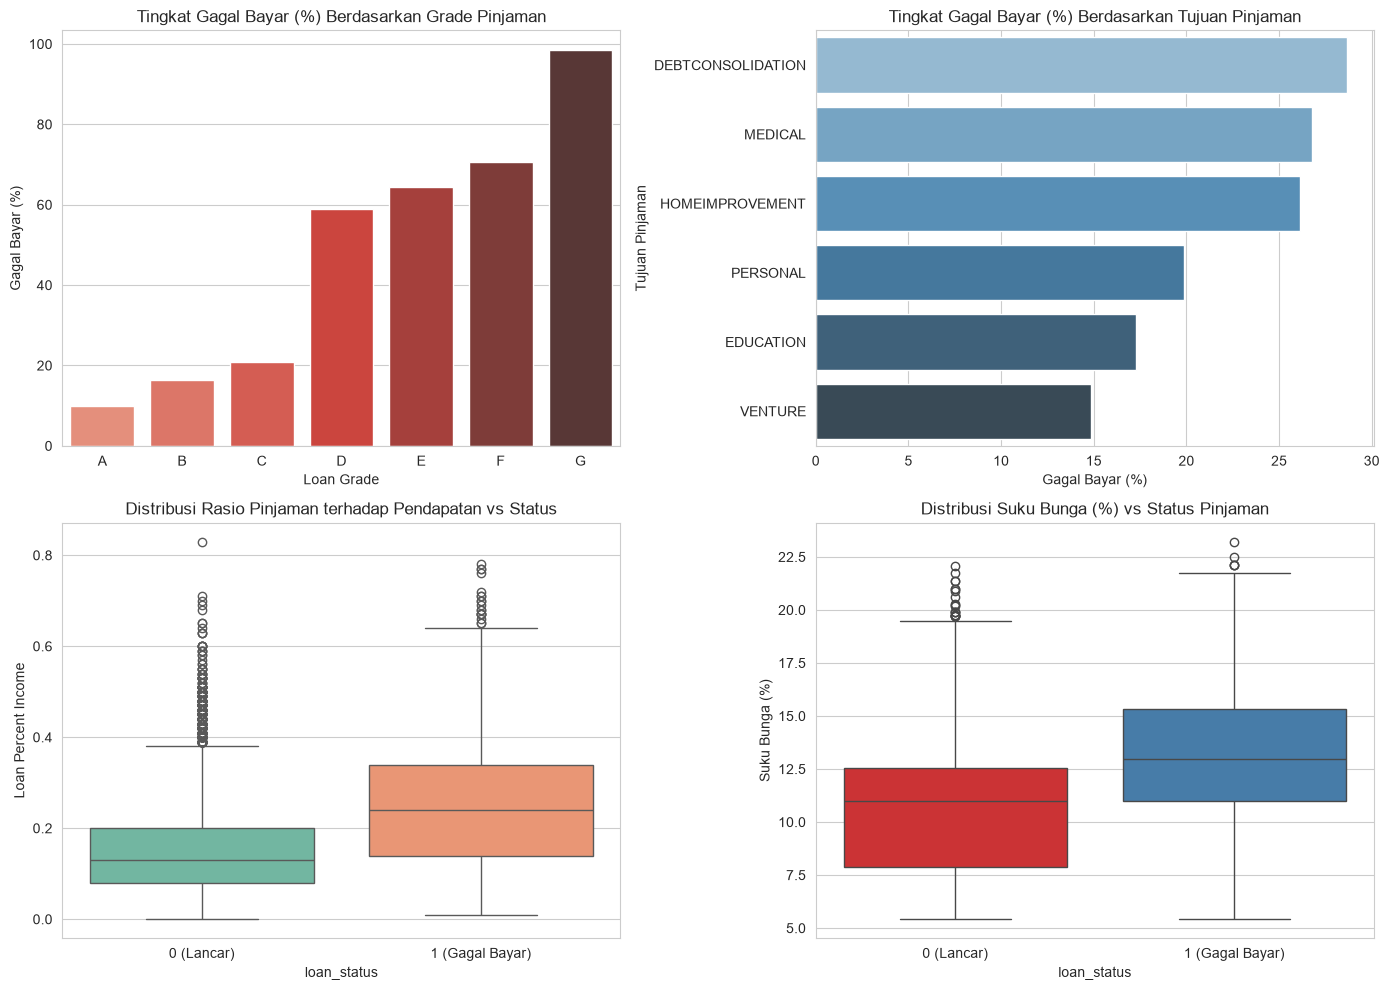

In [67]:
# visualisasi pola pinjaman dan gagal bayar
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Plot 1: Tambahkan hue dan legend=False
sns.barplot(x=grade_default.index, y=grade_default['Persentase_Gagal_Bayar (%)'], hue=grade_default.index, ax=axes[0, 0], palette='Reds_d', legend=False)
axes[0, 0].set_title('Tingkat Gagal Bayar (%) Berdasarkan Grade Pinjaman')
axes[0, 0].set_ylabel('Gagal Bayar (%)')
axes[0, 0].set_xlabel('Loan Grade')

# Plot 2: Tambahkan hue dan legend=False
sns.barplot(y=intent_default.index, x=intent_default['Persentase_Gagal_Bayar (%)'], hue=intent_default.index, ax=axes[0, 1], palette='Blues_d', legend=False)
axes[0, 1].set_title('Tingkat Gagal Bayar (%) Berdasarkan Tujuan Pinjaman')
axes[0, 1].set_xlabel('Gagal Bayar (%)')
axes[0, 1].set_ylabel('Tujuan Pinjaman')

# Plot 3: Tambahkan hue, legend=False, dan set_xticks([0, 1])
sns.boxplot(x='loan_status', y='loan_percent_income', hue='loan_status', data=df_eda, ax=axes[1, 0], palette='Set2', legend=False)
axes[1, 0].set_title('Distribusi Rasio Pinjaman terhadap Pendapatan vs Status')
axes[1, 0].set_xticks([0, 1])
axes[1, 0].set_xticklabels(['0 (Lancar)', '1 (Gagal Bayar)'])
axes[1, 0].set_ylabel('Loan Percent Income')

# Plot 4: Tambahkan hue, legend=False, dan set_xticks([0, 1])
sns.boxplot(x='loan_status', y='loan_int_rate', hue='loan_status', data=df_eda, ax=axes[1, 1], palette='Set1', legend=False)
axes[1, 1].set_title('Distribusi Suku Bunga (%) vs Status Pinjaman')
axes[1, 1].set_xticks([0, 1])
axes[1, 1].set_xticklabels(['0 (Lancar)', '1 (Gagal Bayar)'])
axes[1, 1].set_ylabel('Suku Bunga (%)')

plt.tight_layout()
plt.show()

# 5. Gaussian Naive Bayes Modeling & Evaluasi 10-Fold CV

In [52]:
# membangun pipeline klasifikasi Naive Bayes dengan StandardScaler
pipeline_gnb = make_pipeline(StandardScaler(), GaussianNB())

skf = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
scoring = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']
cv_results = cross_validate(pipeline_gnb, X, y, cv=skf, scoring=scoring)

fold_df = pd.DataFrame({
    'Fold': [f'Fold-{i}' for i in range(1, 11)],
    'Accuracy (%)': (cv_results['test_accuracy'] * 100).round(2),
    'Precision (%)': (cv_results['test_precision'] * 100).round(2),
    'Recall (%)': (cv_results['test_recall'] * 100).round(2),
    'F1-Score (%)': (cv_results['test_f1'] * 100).round(2),
    'ROC-AUC': cv_results['test_roc_auc'].round(4)
})

In [53]:
# menampilkan tabel hasil evaluasi setiap fold (10-Fold Cross Validation)
print("A. Tabel Hasil Evaluasi Setiap Fold (10-Fold Cross Validation)")
display(fold_df)

summary_cv = pd.DataFrame({
    'Metrik Evaluasi': ['Accuracy (%)', 'Precision (%)', 'Recall (%)', 'F1-Score (%)', 'ROC-AUC'],
    'Rata-Rata': [
        round(cv_results['test_accuracy'].mean() * 100, 2),
        round(cv_results['test_precision'].mean() * 100, 2),
        round(cv_results['test_recall'].mean() * 100, 2),
        round(cv_results['test_f1'].mean() * 100, 2),
        round(cv_results['test_roc_auc'].mean(), 4)
    ],
    'Standar Deviasi (±)': [
        round(cv_results['test_accuracy'].std() * 100, 2),
        round(cv_results['test_precision'].std() * 100, 2),
        round(cv_results['test_recall'].std() * 100, 2),
        round(cv_results['test_f1'].std() * 100, 2),
        round(cv_results['test_roc_auc'].std(), 4)
    ]
})

A. Tabel Hasil Evaluasi Setiap Fold (10-Fold Cross Validation)


,Fold,Accuracy (%),Precision (%),Recall (%),F1-Score (%),ROC-AUC
0,Fold-1,81.02,55.40,67.98,61.05,0.8386
1,Fold-2,81.55,56.71,66.15,61.07,0.8323
2,Fold-3,80.53,54.31,69.25,60.88,0.8361
3,Fold-4,80.90,55.29,66.29,60.30,0.8242
4,Fold-5,81.09,55.53,67.98,61.13,0.8397
5,Fold-6,80.75,54.97,66.29,60.10,0.8320
6,Fold-7,80.10,53.70,65.44,59.00,0.8355
7,Fold-8,81.14,55.56,68.50,61.35,0.8306
8,Fold-9,80.71,54.73,67.80,60.57,0.8423
9,Fold-10,81.11,55.54,68.55,61.36,0.8349


In [54]:
# menampilkan ringkasan performa keseluruhan model
print("\nB. Ringkasan Performa Keseluruhan Model")
display(summary_cv)


B. Ringkasan Performa Keseluruhan Model


,Metrik Evaluasi,Rata-Rata,Standar Deviasi (±)
0,Accuracy (%),80.8900,0.3800
1,Precision (%),55.1800,0.7700
2,Recall (%),67.4200,1.2100
3,F1-Score (%),60.6800,0.6900
4,ROC-AUC,0.8346,0.0049


In [55]:
# melakukan prediksi out-of-fold (OOF) untuk evaluasi model
y_pred_oof = cross_val_predict(pipeline_gnb, X, y, cv=skf, method='predict')
y_prob_oof = cross_val_predict(pipeline_gnb, X, y, cv=skf, method='predict_proba')[:, 1]

print("\nC. Classification Report (Akumulasi 10-Fold)")
report_dict = classification_report(y, y_pred_oof, target_names=['0 (Lancar)', '1 (Gagal Bayar)'], output_dict=True)
display(pd.DataFrame(report_dict).transpose().round(4))


C. Classification Report (Akumulasi 10-Fold)


,precision,recall,f1-score,support
0 (Lancar),0.9028,0.8466,0.8738,25319.0000
1 (Gagal Bayar),0.5517,0.6742,0.6068,7088.0000
accuracy,0.8089,0.8089,0.8089,0.8089
macro avg,0.7272,0.7604,0.7403,32407.0000
weighted avg,0.8260,0.8089,0.8154,32407.0000


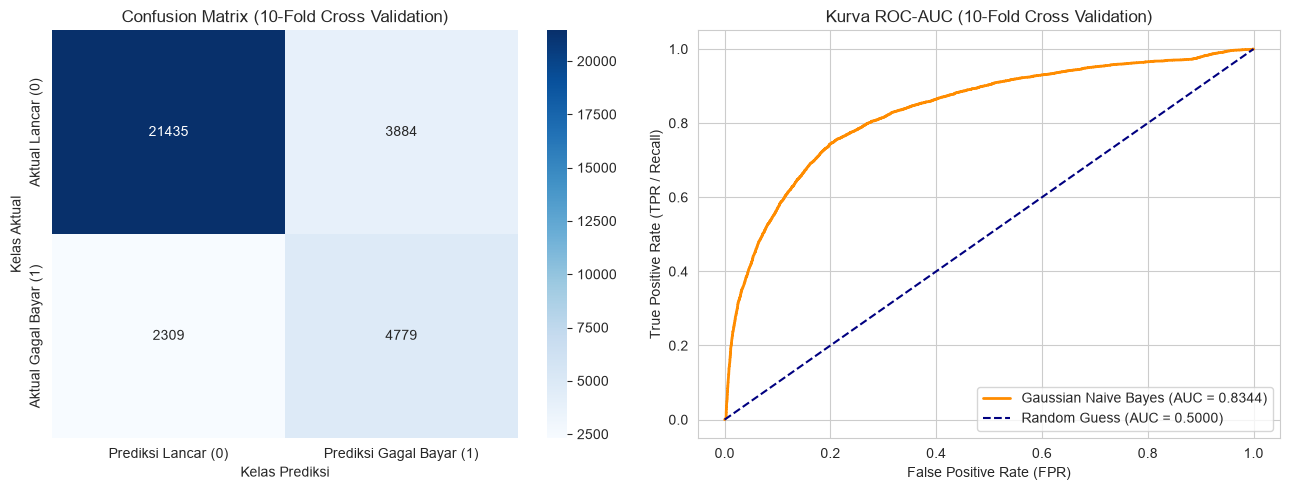

In [56]:
# menampilkan confusion matrix dan kurva ROC-AUC
cm = confusion_matrix(y, y_pred_oof)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Prediksi Lancar (0)', 'Prediksi Gagal Bayar (1)'],
            yticklabels=['Aktual Lancar (0)', 'Aktual Gagal Bayar (1)'])
axes[0].set_title('Confusion Matrix (10-Fold Cross Validation)')
axes[0].set_ylabel('Kelas Aktual')
axes[0].set_xlabel('Kelas Prediksi')

fpr, tpr, _ = roc_curve(y, y_prob_oof)
auc_score = roc_auc_score(y, y_prob_oof)
axes[1].plot(fpr, tpr, color='darkorange', lw=2, label=f'Gaussian Naive Bayes (AUC = {auc_score:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guess (AUC = 0.5000)')
axes[1].set_title('Kurva ROC-AUC (10-Fold Cross Validation)')
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR / Recall)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

# 6. Menentukan Faktor yang Paling Berpengaruh

In [57]:
# melatih model Gaussian Naive Bayes pada seluruh dataset
pipeline_gnb.fit(X, y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('gaussiannb', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](17,)","['person_age','person_income','person_emp_length',..., 'loan_intent_MEDICAL','loan_intent_PERSONAL','loan_intent_VENTURE']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,17
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [58]:
# melakukan evaluasi pentingnya fitur menggunakan Permutation Importance
perm_auc = permutation_importance(pipeline_gnb, X, y, n_repeats=15, random_state=42, scoring='roc_auc')

In [59]:
# menghitung Fisher's Separation Score untuk setiap fitur
scaler_full = StandardScaler()
X_scaled_full = scaler_full.fit_transform(X)
gnb_full = GaussianNB()
gnb_full.fit(X_scaled_full, y)

mu_0, mu_1 = gnb_full.theta_[0], gnb_full.theta_[1]
var_0, var_1 = gnb_full.var_[0], gnb_full.var_[1]
fisher_score = np.abs(mu_1 - mu_0) / np.sqrt(var_1 + var_0)

importance_df = pd.DataFrame({
    'Fitur': X.columns,
    'Perm_Importance_AUC': perm_auc.importances_mean.round(4),
    'Fisher_Separation_Score': fisher_score.round(4)
}).sort_values(by='Perm_Importance_AUC', ascending=False).reset_index(drop=True)

In [60]:
# Menampilkan peringkat faktor paling berpengaruh terhadap risiko gagal bayar
print("Peringkat Faktor Paling Berpengaruh terhadap Risiko Gagal Bayar")
display(importance_df)

Peringkat Faktor Paling Berpengaruh terhadap Risiko Gagal Bayar


,Fitur,Perm_Importance_AUC,Fisher_Separation_Score
0,loan_percent_income,0.0671,0.6196
1,person_home_ownership_OWN,0.0440,0.1996
2,loan_grade,0.0323,0.6266
3,person_income,0.0195,0.3249
4,person_home_ownership_RENT,0.0129,0.4324
5,loan_int_rate,0.0122,0.5585
6,loan_intent_VENTURE,0.0076,0.1412
7,loan_intent_EDUCATION,0.0026,0.0980
8,loan_intent_HOMEIMPROVEMENT,0.0021,0.0608
9,loan_amnt,0.0021,0.1729


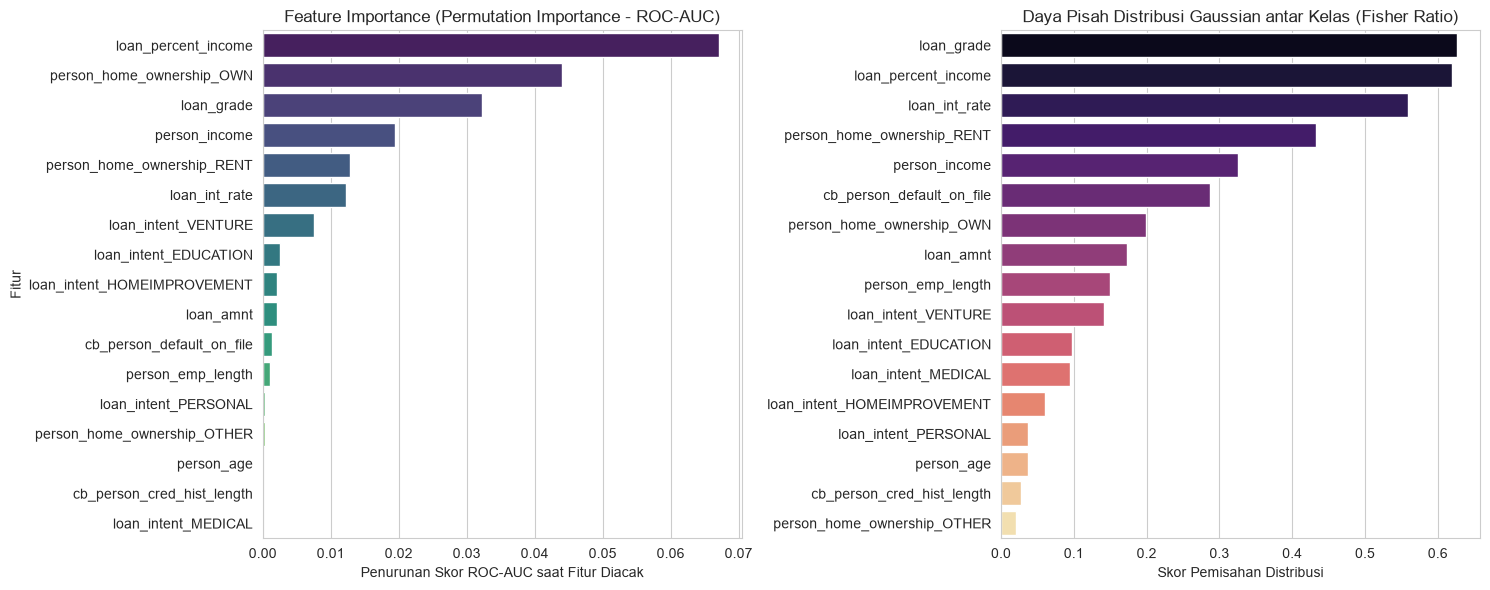

In [68]:
# menampilkan visualisasi pentingnya fitur berdasarkan Permutation Importance dan Fisher's Separation Score
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Plot 1: Tambahkan hue='Fitur' dan legend=False
sns.barplot(x='Perm_Importance_AUC', y='Fitur', hue='Fitur', data=importance_df, ax=axes[0], palette='viridis', legend=False)
axes[0].set_title('Feature Importance (Permutation Importance - ROC-AUC)')
axes[0].set_xlabel('Penurunan Skor ROC-AUC saat Fitur Diacak')
axes[0].set_ylabel('Fitur')

# Plot 2: Tambahkan hue='Fitur' dan legend=False
imp_fisher = importance_df.sort_values(by='Fisher_Separation_Score', ascending=False)
sns.barplot(x='Fisher_Separation_Score', y='Fitur', hue='Fitur', data=imp_fisher, ax=axes[1], palette='magma', legend=False)
axes[1].set_title('Daya Pisah Distribusi Gaussian antar Kelas (Fisher Ratio)')
axes[1].set_xlabel('Skor Pemisahan Distribusi')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# 7. Simulasi Prediksi pada Sampel Kasus Nyata

Simulasi Pengujian Kasus Nyata (Studi Kasus Pemohon Kredit)

Untuk menguji kinerja model **Gaussian Naive Bayes** dalam skenario pengambilan keputusan nyata, dilakukan simulasi prediksi terhadap profil seorang calon peminjam dengan karakteristik sebagai berikut:

* **Profil Demografis & Pekerjaan:** Seorang pemohon berusia **25 tahun** (`person_age = 25`), saat ini tinggal di rumah sewa (`person_home_ownership = RENT`), dan baru memiliki pengalaman kerja selama **1 tahun** (`person_emp_length = 1.0`) dengan total pendapatan tahunan sebesar **$9.600** (`person_income = 9600`).
* **Riwayat Kredit:** Pemohon telah memiliki riwayat kredit selama **3 tahun** (`cb_person_cred_hist_length = 3`) dan belum pernah tercatat mengalami gagal bayar sebelumnya (`cb_person_default_on_file = N`).
* **Detail Pengajuan Pinjaman:** Pemohon mengajukan pinjaman sebesar **$5.500** (`loan_amnt = 5500`) untuk kebutuhan biaya pengobatan/medis (`loan_intent = MEDICAL`). Pinjaman tersebut masuk dalam kategori peringkat **Grade C** (`loan_grade = 2`) dengan tingkat suku bunga sebesar **12,87%** (`loan_int_rate = 12.87`), sehingga rasio jumlah pinjaman terhadap pendapatan tahunannya mencapai **57%** (`loan_percent_income = 0.57`).

In [62]:
# melakukan prediksi pada contoh sampel kasus nyata
sample_case = pd.DataFrame([{
    'person_age': 25,
    'person_income': 9600,
    'person_emp_length': 1.0,
    'loan_grade': 2,                # Grade C
    'loan_amnt': 5500,
    'loan_int_rate': 12.87,
    'loan_percent_income': 0.57,
    'cb_person_default_on_file': 0, # N
    'cb_person_cred_hist_length': 3,
    'person_home_ownership_OTHER': 0,
    'person_home_ownership_OWN': 0,
    'person_home_ownership_RENT': 1,
    'loan_intent_DEBTCONSOLIDATION': 0,
    'loan_intent_EDUCATION': 0,
    'loan_intent_HOMEIMPROVEMENT': 0,
    'loan_intent_MEDICAL': 1,
    'loan_intent_PERSONAL': 0,
    'loan_intent_VENTURE': 0
}])[X.columns]

pred_class = pipeline_gnb.predict(sample_case)[0]
pred_proba = pipeline_gnb.predict_proba(sample_case)[0]

In [63]:
# menampilkan hasil prediksi dari contoh sampel kasus nyata
print("\nHasil Prediksi Sampel Contoh:")
print(f"Hasil Klasifikasi : Kelas {pred_class} -> {'GAGAL BAYAR (Risiko Tinggi)' if pred_class == 1 else 'LANCAR (Risiko Rendah)'}")
print(f"Probabilitas      : Lancar (0) = {pred_proba[0]*100:.2f}% | Gagal Bayar (1) = {pred_proba[1]*100:.2f}%")


Hasil Prediksi Sampel Contoh:
Hasil Klasifikasi : Kelas 1 -> GAGAL BAYAR (Risiko Tinggi)
Probabilitas      : Lancar (0) = 0.01% | Gagal Bayar (1) = 99.99%


**Hasil Prediksi Model:**
Berdasarkan kombinasi atribut tersebut—terutama tingginya beban rasio utang terhadap pendapatan (57%) dan status tempat tinggal sewa. Model mengklasifikasikan pemohon ke dalam **Kelas `1` (Gagal Bayar / Risiko Tinggi)** dengan probabilitas risiko gagal bayar sebesar **99,99%** (berbanding **0,01%** peluang lancar).

# 8. Rekomendasi untuk Manajemen

In [64]:
# menampilkan ringkasan temuan utama dan rekomendasi kebijakan manajemen
rekomendasi = pd.DataFrame({
    'No': [1, 2, 3, 4, 5],
    'Temuan Utama Data & Model': [
        'loan_percent_income menjadi faktor paling berpengaruh (rata-rata gagal bayar 25% vs lancar 15%)',
        'Lonjakan tajam tingkat gagal bayar mulai Grade D (59,05%) hingga Grade G (98,44%)',
        'Status rumah sewa (RENT) memiliki risiko gagal bayar 31,61% (4x lebih tinggi dari pemilik rumah)',
        'Tujuan konsolidasi utang (28,68%) & medis (26,77%) paling rawan macet dibanding modal usaha (14,86%)',
        'Model Gaussian NB mencapai ROC-AUC 0,8346 & menangkap 67,42% kasus gagal bayar secara instan'
    ],
    'Rekomendasi Kebijakan Manajemen': [
        'Tetapkan batas maksimal rasio pinjaman terhadap pendapatan (Debt-to-Income Cap) sebesar 20-25% tanpa agunan.',
        'Wajibkan agunan tambahan untuk pinjaman Grade D dan hentikan persetujuan kredit tanpa agunan pada Grade E-G.',
        'Terapkan verifikasi masa kerja minimal (person_emp_length >= 2 tahun) bagi pemohon berstatus rumah sewa (RENT).',
        'Berikan skema tenor lebih panjang dengan cicilan ringan untuk pinjaman medis/konsolidasi utang guna menekan gagal bayar.',
        'Integrasikan model Gaussian Naive Bayes sebagai sistem Early Screening otomatis pada tahap awal pengajuan kredit.'
    ]
})
display(rekomendasi)

,No,Temuan Utama Data & Model,Rekomendasi Kebijakan Manajemen
0,1,loan_percent_income menjadi faktor paling berp...,Tetapkan batas maksimal rasio pinjaman terhada...
1,2,Lonjakan tajam tingkat gagal bayar mulai Grade...,Wajibkan agunan tambahan untuk pinjaman Grade ...
2,3,Status rumah sewa (RENT) memiliki risiko gagal...,Terapkan verifikasi masa kerja minimal (person...
3,4,"Tujuan konsolidasi utang (28,68%) & medis (26,...",Berikan skema tenor lebih panjang dengan cicil...
4,5,"Model Gaussian NB mencapai ROC-AUC 0,8346 & me...",Integrasikan model Gaussian Naive Bayes sebaga...
